# 02 - Motion model (optical flow): baselines, MotionNetV2, validation-based selection
**Question answered: HOW ARE THEY MOVING?** (pixel-level motion).   Self-contained notebook.

| | |
|---|---|
| **Reads** | TUB CrowdFlow (`images/`, `gt_flow/`, `masks/`) under `DATASET_ROOT` |
| **Writes** | `<OUTPUT_DIR>/models/motion_model.pth`, `models/flow_selection.json`, `outputs/metrics/scene_split.json` + motion metrics / figures |
| **Next** | `03_Abnormal_Motion_Detection` |

### Logic (preserved from the original notebook 03)
* **Scene-group split:** `IM03` and `IM03_hDyn` form one group; whole groups go to TRAIN / VALIDATION / TEST, frames of one scene never leak across splits.
* **Estimators compared:** zero-flow baseline, Farneback, DIS, optional pretrained RAFT-small, and **MotionNetV2** (small U-Net that *refines* DIS flow; residual output with zero-initialised head, so it starts at the classical result and can only improve on it by learning).
* **Metrics:** EPE (all pixels), **masked EPE** (inside the crowd mask - the region that matters), MAE, RMSE, angular error, direction consistency.
* **Selection on validation only:** the estimator with the lowest *validation masked EPE* among the non-zero estimators is used. Neither MotionNetV2 nor DIS is assumed to be better. `BASELINE` = best classical estimator; `ENHANCED` = MotionNetV2 (selected only if it is better).
* The working resolution is also chosen on validation (DIS vs the zero-flow baseline inside the mask).
* Ground-truth flow is used for **training and evaluation only**; real-video inference (notebook 04) uses predicted flow.

## 0. Configuration

In [1]:
# ============================================================
# USER CONFIGURATION   (the only cell you normally need to edit)
# ============================================================
import os
NOTEBOOK_NAME = "02_Motion_Model"
DATASET_ROOT = r"C:\main project\stampede-risk-estimation\data\raw"     # folder that CONTAINS 'tubcrowdflow' (and 'shanghaitech'); searched automatically (~4 levels deep)
OUTPUT_DIR = "./crowdrisk_outputs"      # USE THE SAME FOLDER IN ALL FOUR NOTEBOOKS: trained models / metrics are exchanged through <OUTPUT_DIR>/models and <OUTPUT_DIR>/outputs
SEED = 42
USE_GPU = True                          # True -> CUDA if available, otherwise CPU

TRAIN_MOTION_MODEL = True    # False -> load <OUTPUT_DIR>/models/motion_model.pth (classical estimators are always evaluated)
MOTION_TRAIN = None          # None -> automatic (GPU: 30 epochs / CPU: 10 epochs); or a dict like dict(epochs=20, items_per_epoch=1200, batch=8, crop=192, base=24, lr=1e-3)
MOTION_WIDTHS = [256, 384, 512, 640]     # working widths compared on validation
USE_RAFT = True              # optional pretrained RAFT-small (needs a one-time weight download; skipped gracefully if unavailable)
SMOKE_TEST = os.environ.get("CROWDRISK_SMOKE", "0") == "1"   # True: tiny SYNTHETIC datasets + tiny models (checks the code path in minutes; metrics are meaningless)


In [2]:
# ---- SMOKE TEST mode (optional): everything below is replaced by tiny synthetic datasets / models so the WHOLE notebook runs in minutes ----
import tempfile
if SMOKE_TEST:
    _SMOKE_BASE = os.path.join(tempfile.gettempdir(), "crowdrisk_smoke")
    DATASET_ROOT = os.path.join(_SMOKE_BASE, "data", "raw"); NEGATIVE_DIR = os.path.join(_SMOKE_BASE, "shanghai_negative_sampling")
    if OUTPUT_DIR == "./crowdrisk_outputs": OUTPUT_DIR = os.path.join(_SMOKE_BASE, "outputs")
    WINDOW_LEN, HOP, FPS = 12, 4, 15.0; COUNT_PRESET = "smoke"; MOTION_WIDTHS = [96, 144, 192]; USE_RAFT = False; COUNT_STRIDE_TRAINING = 6; COUNT_EVERY = 3
    MOTION_TRAIN = dict(epochs=2, items_per_epoch=16, batch=4, crop=96, base=8, lr=1e-3); NEG_FRACTION = 0.3; VIDEO_PATH = None
    print("*** SMOKE TEST: synthetic data in", _SMOKE_BASE, "- code-path check only, all metrics are meaningless ***")


## 1. Environment and dependencies

In [3]:
# ---- dependency check: installs ONLY what is missing (a one-time `pip install torch torchvision` can be large) ---------------------
import sys, importlib, importlib.util, subprocess
_need = {"numpy": "numpy", "scipy": "scipy", "pandas": "pandas", "cv2": "opencv-python", "matplotlib": "matplotlib", "sklearn": "scikit-learn", "tqdm": "tqdm",
         "joblib": "joblib", "torch": "torch", "torchvision": "torchvision", "PIL": "pillow", "lightgbm": "lightgbm"}
if not NOTEBOOK_NAME.startswith("04"): _need.pop("lightgbm")                 # only the risk notebook needs the tree-model packages
_missing = [pip for mod, pip in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("installing:", _missing)
    try: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
    except Exception as e: print(f"[WARNING] automatic install failed ({e}). Run in a terminal, then restart the kernel:\n    {sys.executable} -m pip install " + " ".join(_missing))
else: print("all required packages are installed")
for _opt, _why in ((("lightgbm", "LightGBM risk model (falls back to XGBoost / scikit-learn HistGradientBoosting)"), ("xgboost", "XGBoost fallback")) if NOTEBOOK_NAME.startswith("04") else ()):
    if importlib.util.find_spec(_opt) is None: print(f"[info] optional package '{_opt}' not installed -> {_why}")


all required packages are installed


In [4]:
# ---- from notebook 00 cell 4
# ============================================================================
# Imports, environment helpers (portable: Colab / VS Code / plain Jupyter)
# ============================================================================
import os, sys, io, math, time, json, glob, copy, random, shutil, hashlib, warnings, zipfile, tempfile
import numpy as np, pandas as pd, cv2, scipy.io as sio
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from scipy.ndimage import maximum_filter
import matplotlib
if os.environ.get("CC_HEADLESS"): matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps
from tqdm.auto import tqdm
warnings.filterwarnings("ignore"); cv2.setNumThreads(1)
IN_COLAB = "google.colab" in sys.modules

def pick_device(pref="auto"):
    """'auto' -> CUDA if available else CPU. Never hard-codes CUDA."""
    pref = (pref or "auto").lower()
    if pref == "cpu": return torch.device("cpu")
    if torch.cuda.is_available(): return torch.device("cuda")
    if pref in ("cuda", "gpu"): print("[warn] CUDA was requested but is not available -> using CPU.")
    return torch.device("cpu")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def json_safe(o):
    """Recursively convert numpy / tuple / Path objects into JSON-compatible python types."""
    if isinstance(o, dict): return {str(k): json_safe(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [json_safe(v) for v in o]
    if isinstance(o, np.generic): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (str, int, float, bool)) or o is None: return o
    return str(o)

def save_atomic(obj, path):
    tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)

def torch_load_safe(path, device):
    try: return torch.load(path, map_location=device, weights_only=True)
    except Exception: return torch.load(path, map_location=device, weights_only=False)      # our own files only

def ceil_to(x, m=32): return int(math.ceil(x / m) * m)

try: from IPython.display import display, Markdown
except Exception:
    display = print
    def Markdown(x): return x

# ---------------------------------------------------------------- default inference / refinement settings (shared by both notebooks)
DEFAULT_REFINE = dict(
    enabled=True, region_size=128,      # px (original image) of the analysis grid cells
    min_region_density=6.0,             # ignore regions whose density estimate is below this many people
    abs_gap=3.0, rel_gap=0.30,          # flag if (density - accepted points) >= max(abs_gap, rel_gap*density)
    min_uncertain=3,                    # ... or if >= this many uncertain (yellow) points sit in the region
    crop_margin=32,                     # px of context added around the region (overlap with neighbours)
    scale=2.0, scale_growth=1.5, max_scale=3.0,   # effective-resolution multiplier on iteration 0, growth per iteration, hard cap
    max_iters=2, max_regions=12,        # max refinement iterations / max regions re-analysed per image
    max_crop_pixels=1.5e6,              # memory guard for the up-scaled crop
    policy="replace_if_more")           # 'union' | 'replace_if_more' | 'replace'  (see _merge_region)

DEFAULT_INFER = dict(
    density_scale=10.0, min_long=640, max_long=1536, max_pixels=2.0e6, tile=768, tile_overlap=128,
    exposure_norm=True, exposure_target=0.42, min_candidate_conf=0.05, peak_min_value=0.01, amp=False,
    conf_accept=0.5, uncertain_ratio=0.5, dup_radius=3.0, refine=copy.deepcopy(DEFAULT_REFINE))




# ---- extra imports used by the motion / risk parts --------------------------------------------------------------------------------
import re, struct, datetime, dataclasses
from dataclasses import dataclass, field
from collections import deque
from scipy.ndimage import gaussian_filter, binary_dilation
import joblib
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score, average_precision_score, f1_score, roc_curve, precision_recall_curve, classification_report)


c:\main project\stampede-risk-estimation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
# ---- run folders, seeds, device, reproducibility record (the SAME OUTPUT_DIR is used by all four notebooks) -----------------------------------------
import datetime
SEED = int(SEED); set_seed(SEED)
OUTPUT_DIR = os.path.abspath(OUTPUT_DIR)
MODELS_DIR = os.path.join(OUTPUT_DIR, "models")
OUTPUTS = os.path.join(OUTPUT_DIR, "outputs")
METRICS_DIR, FIG_DIR, VIDEO_DIR, PRED_DIR = (os.path.join(OUTPUTS, d) for d in ("metrics", "figures", "videos", "predictions"))
WORK_DIR = os.path.join(OUTPUT_DIR, "work")                        # caches / checkpoints / extracted files (safe to delete, will be rebuilt)
COUNT_OUT = os.path.join(WORK_DIR, "count")                        # crowd-count training work folder (checkpoints, caches, tables)
CACHE_DIR = os.path.join(WORK_DIR, "cache")                        # TUB work-resolution cache + count cache
VIDEO_IN_DIR = os.path.join(OUTPUT_DIR, "videos_in")
for _d in (MODELS_DIR, METRICS_DIR, FIG_DIR, VIDEO_DIR, PRED_DIR, WORK_DIR, COUNT_OUT, CACHE_DIR, VIDEO_IN_DIR): os.makedirs(_d, exist_ok=True)
DEVICE = pick_device("auto" if USE_GPU else "cpu")
if DEVICE.type == "cuda": torch.backends.cudnn.benchmark = True
RUN_META = dict(notebook=NOTEBOOK_NAME, created=datetime.datetime.now().isoformat(timespec="seconds"), seed=SEED, device=str(DEVICE), smoke_test=SMOKE_TEST, torch=torch.__version__)
print(f"[{NOTEBOOK_NAME}] seed {SEED} | device {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else " (CPU only)") + f" | OUTPUT_DIR = {OUTPUT_DIR}")
print("trained models are exchanged between the notebooks through", MODELS_DIR)


[02_Motion_Model] seed 42 | device cpu (CPU only) | OUTPUT_DIR = c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs
trained models are exchanged between the notebooks through c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\models


## 2. TUB CrowdFlow dataset discovery (notebook-local reader)

In [6]:
def _is_dir(p) -> bool:
    try: return os.path.isdir(p)
    except OSError: return False


def _has_shanghai(d: str) -> bool:
    if not _is_dir(d): return False
    names = {n.lower() for n in os.listdir(d)}
    return any(n.startswith("part_a") for n in names) and any(n.startswith("part_b") for n in names)


def _has_tub(d: str) -> bool:
    if not _is_dir(d): return False
    names = {n.lower() for n in os.listdir(d)}
    return ("images" in names or "image" in names) and any(n in names for n in ("gt_flow", "flow", "flows"))


def _find_child(parent: str, names):
    if not _is_dir(parent): return None
    low = {n.lower(): n for n in os.listdir(parent)}
    for n in names:
        if n.lower() in low: return os.path.join(parent, low[n.lower()])
    return None


def _bounded_walk(base: str, max_depth: int, test, skip=("node_modules", ".git", "__pycache__", "site-packages")):
    """Return first directory below `base` (depth <= max_depth) for which test(dir) is true."""
    base = os.path.abspath(base)
    if not _is_dir(base): return None
    if test(base): return base
    queue = [(base, 0)]
    while queue:
        cur, depth = queue.pop(0)
        if depth >= max_depth: continue
        try: kids = sorted(os.listdir(cur))
        except OSError: continue
        for k in kids:
            if k in skip or k.startswith("."): continue
            p = os.path.join(cur, k)
            if not _is_dir(p): continue
            if test(p): return p
            queue.append((p, depth + 1))
    return None


In [7]:
TUB_IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

FLO_MAGIC = 202021.25


def read_flo(path):
    with open(path, "rb") as f:
        magic = struct.unpack("<f", f.read(4))[0]
        if abs(magic - FLO_MAGIC) > 1e-3: raise ValueError(f"{path}: not a valid .flo file (magic={magic})")
        w, h = struct.unpack("<ii", f.read(8))
        if not (0 < w < 20000 and 0 < h < 20000): raise ValueError(f"{path}: invalid size {w}x{h}")
        data = np.frombuffer(f.read(w * h * 2 * 4), dtype="<f4")
    if data.size != w * h * 2: raise ValueError(f"{path}: truncated .flo file")
    return data.reshape(h, w, 2).astype(np.float32)


def write_flo(path, flow):
    h, w = flow.shape[:2]
    with open(path, "wb") as f:
        f.write(struct.pack("<f", FLO_MAGIC)); f.write(struct.pack("<ii", w, h)); f.write(np.ascontiguousarray(flow, dtype="<f4").tobytes())


def _num_key(p):
    nums = re.findall(r"\d+", os.path.basename(p)); return (int(nums[-1]) if nums else -1, os.path.basename(p))


def _list(d, exts):
    if not d or not os.path.isdir(d): return []
    out = [os.path.join(d, f) for f in os.listdir(d) if f.lower().endswith(exts)]
    return sorted(out, key=_num_key)


def base_scene(name):
    """'IM03_hDyn' -> 'IM03'. A scene and its '_hDyn' variant are grouped together for splitting (they most likely share content)."""
    return re.sub(r"[_\-]?hdyn$", "", name, flags=re.I)


def work_size(orig_w, orig_h, work_width=320):
    w = int(work_width); h = int(round(orig_h * w / orig_w / 2.0) * 2); return w, max(h, 16)


class Scene:
    """One TUB CrowdFlow sequence. Pairs: flow j  <->  frames (j, j+1)."""
    def __init__(self, name, images, flows, masks, traj_file):
        self.name, self.group = name, base_scene(name)
        self.images, self.flows, self.masks, self.traj_file = images, flows, masks, traj_file
        n_img, n_flow = len(images), len(flows)
        self.n_pairs = min(n_flow, n_img - 1) if n_flow else max(n_img - 1, 0)
        self.has_flow = n_flow > 0
        self.pair_note = ("flows == frames-1 (standard)" if n_flow == n_img - 1 else
                          f"flows ({n_flow}) != frames-1 ({n_img - 1}): using the first {self.n_pairs} pairs; check the dataset" if n_flow else "no flow files")
        self._size = None

    def __repr__(self): return f"Scene({self.name}, frames={len(self.images)}, flows={len(self.flows)}, masks={len(self.masks)}, group={self.group})"

    @property
    def orig_size(self):
        if self._size is None:
            im = cv2.imread(self.images[0]); assert im is not None, f"cannot read {self.images[0]}"
            self._size = (im.shape[1], im.shape[0])
        return self._size

    def frame(self, i, wsize=None):
        im = cv2.imread(self.images[i], cv2.IMREAD_COLOR)
        if im is None: raise IOError(f"cannot read image {self.images[i]}")
        im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        return cv2.resize(im, wsize, interpolation=cv2.INTER_AREA) if wsize else im

    def gt_flow(self, j, wsize=None):
        """Ground-truth flow of pair j resized to `wsize`; the VECTORS are rescaled by the same factors (flow is in pixels)."""
        fl = read_flo(self.flows[j]); h, w = fl.shape[:2]
        if wsize and (wsize[0] != w or wsize[1] != h):
            fl = cv2.resize(fl, wsize, interpolation=cv2.INTER_AREA); fl[..., 0] *= wsize[0] / w; fl[..., 1] *= wsize[1] / h
        return fl

    def mask(self, j, wsize=None):
        if not self.masks: return None
        k = min(j, len(self.masks) - 1); m = cv2.imread(self.masks[k], cv2.IMREAD_UNCHANGED)
        if m is None: return None
        if m.ndim == 3: m = m.max(axis=2)
        m = (m > 0).astype(np.uint8)
        return cv2.resize(m, wsize, interpolation=cv2.INTER_NEAREST).astype(bool) if wsize else m.astype(bool)


def discover_scenes(paths, verbose=True):
    """Scenes found under <tub>/images/<scene>/ (same structure the original motion notebook used)."""
    if not paths.tub_images or not os.path.isdir(paths.tub_images): raise FileNotFoundError("TUB CrowdFlow images folder not found (see the startup path report).")
    scenes = []
    for name in sorted(os.listdir(paths.tub_images)):
        d = os.path.join(paths.tub_images, name)
        if not os.path.isdir(d): continue
        imgs = _list(d, TUB_IMG_EXT); flows = _list(os.path.join(paths.tub_flow, name), (".flo",)) if paths.tub_flow else []
        masks = _list(os.path.join(paths.tub_masks, name), TUB_IMG_EXT) if paths.tub_masks else []
        tf = None
        if paths.tub_traj and os.path.isdir(os.path.join(paths.tub_traj, name)):
            cands = sorted(glob.glob(os.path.join(paths.tub_traj, name, "*.mat")))
            pref = [c for c in cands if "dense" in os.path.basename(c).lower()]; tf = (pref or cands or [None])[0]
        if len(imgs) >= 2: scenes.append(Scene(name, imgs, flows, masks, tf))
    if not scenes: raise RuntimeError(f"No scenes with >= 2 images under {paths.tub_images}")
    if verbose:
        print(f"TUB CrowdFlow: {len(scenes)} scenes -> groups: {sorted({s.group for s in scenes})}")
        for s in scenes: print(f"  {s.name:<14} frames={len(s.images):4d} flows={len(s.flows):4d} masks={len(s.masks):4d} traj={'yes' if s.traj_file else 'no '} | {s.pair_note}")
    return scenes


# ------------------------------------------------------------------------------------------------ trajectories
def load_trajectories(scene, layout="auto", max_tracks=4000, seed=0):
    """Dense trajectories -> array (T, N, 2) in ORIGINAL image pixels, NaN where a track is not defined.
    The .mat variable is a (N_tracks, 2*T) matrix. Whether columns are interleaved (x0,y0,x1,y1,...) or blocked (x0..xT, y0..yT) is
    detected automatically (the layout with the smoother tracks wins) unless `layout` is given. Returns (tracks, info_dict)."""
    import scipy.io as sio
    if not scene.traj_file: return None, dict(note="no trajectory file")
    d = sio.loadmat(scene.traj_file)
    key = "matTrajectsCopy" if "matTrajectsCopy" in d else next((k for k, v in d.items() if not k.startswith("__") and isinstance(v, np.ndarray) and v.ndim == 2), None)
    if key is None: return None, dict(note="no 2-D array in the .mat file")
    M = np.asarray(d[key], dtype=np.float64)
    if M.shape[1] % 2 and M.shape[0] % 2 == 0: M = M.T
    N, C = M.shape; T = C // 2; W, H = scene.orig_size
    rng = np.random.default_rng(seed)
    if N > max_tracks: M = M[rng.choice(N, max_tracks, replace=False)]
    def build(lay):
        x, y = (M[:, 0::2], M[:, 1::2]) if lay == "interleaved" else (M[:, :T], M[:, T:2 * T])
        t = np.stack([x, y], -1).transpose(1, 0, 2).copy()           # (T, N, 2)
        bad = ~np.isfinite(t).all(-1) | ((t[..., 0] == 0) & (t[..., 1] == 0)) | (t[..., 0] < -W) | (t[..., 0] > 2 * W) | (t[..., 1] < -H) | (t[..., 1] > 2 * H)
        t[bad] = np.nan; return t
    cands = {l: build(l) for l in ("interleaved", "blocked")}
    def roughness(t):
        s = np.linalg.norm(np.diff(t, axis=0), axis=-1); s = s[np.isfinite(s)]
        return float(np.median(s)) if s.size else np.inf
    rough = {l: roughness(t) for l, t in cands.items()}
    chosen = layout if layout in cands else min(rough, key=rough.get)
    tr = cands[chosen]; valid = float(np.isfinite(tr[..., 0]).mean())
    return tr.astype(np.float32), dict(key=key, shape_mat=(N, C), T=T, layout=chosen, roughness=rough, valid_fraction=valid, frames_in_scene=len(scene.images),
                                      note=("trajectory length matches the number of frames" if T == len(scene.images) else f"trajectory length T={T} != frames {len(scene.images)}"))


# ------------------------------------------------------------------------------------------------ sequence-aware splitting
def split_groups(groups, seed=42, n_val=1, n_test=1):
    """Split SCENE GROUPS (never individual frames) into train / val / test. 'IM03' and 'IM03_hDyn' always stay together."""
    gs = sorted(set(groups)); rng = np.random.default_rng(seed); perm = list(rng.permutation(len(gs)))
    n_test = min(n_test, max(len(gs) - 2, 0)); n_val = min(n_val, max(len(gs) - n_test - 1, 0))
    test = [gs[i] for i in perm[:n_test]]; val = [gs[i] for i in perm[n_test:n_test + n_val]]; train = [gs[i] for i in perm[n_test + n_val:]]
    return dict(train=sorted(train), val=sorted(val), test=sorted(test))


def logo_folds(groups, seed=42):
    """Leave-one-scene-group-out: for each held-out group (test) one other group is validation, the rest train."""
    gs = sorted(set(groups)); rng = np.random.default_rng(seed); folds = []
    for g in gs:
        rest = [x for x in gs if x != g]; v = rest[int(rng.integers(len(rest)))] if len(rest) > 1 else None
        folds.append(dict(test=[g], val=[v] if v else [], train=[x for x in rest if x != v]))
    return folds


def print_split(split, scenes):
    by_g = {}
    for s in scenes: by_g.setdefault(s.group, []).append(s.name)
    print("SEQUENCE-LEVEL SPLIT (no frame of a scene appears in more than one subset):")
    for k in ("train", "val", "test"):
        names = [n for g in split.get(k, []) for n in by_g.get(g, [])]
        frames = sum(len(s.images) for s in scenes if s.group in split.get(k, []))
        print(f"  {k.upper():<6} groups={split.get(k, [])}  scenes={names}  frames={frames}")
    allg = [g for k in ("train", "val", "test") for g in split.get(k, [])]
    assert len(allg) == len(set(allg)), "LEAK: a scene group appears in more than one subset"


def scenes_of(scenes, groups): return [s for s in scenes if s.group in set(groups)]


def audit_tub(scenes, max_check=12):
    """Per-scene audit table (counts, sizes, readability of a sample of .flo files, NaNs, trajectory layout)."""
    import pandas as pd
    rows = []
    for s in scenes:
        r = dict(scene=s.name, group=s.group, frames=len(s.images), flows=len(s.flows), masks=len(s.masks), has_traj=bool(s.traj_file), pair_note=s.pair_note)
        try: r["width"], r["height"] = s.orig_size
        except Exception as e: r["issue_image"] = str(e)
        bad, nan, mags = 0, 0, []
        idx = np.linspace(0, max(len(s.flows) - 1, 0), min(max_check, len(s.flows))).astype(int) if s.flows else []
        for j in idx:
            try:
                f = read_flo(s.flows[j]); nan += int(~np.isfinite(f).all()); mags.append(float(np.nanmean(np.linalg.norm(f, axis=-1))))
            except Exception: bad += 1
        r.update(flo_unreadable_in_sample=bad, flo_with_nan_in_sample=nan, mean_flow_px_sample=float(np.mean(mags)) if mags else np.nan)
        if s.traj_file:
            try:
                tr, info = load_trajectories(s, max_tracks=500); r.update(traj_layout=info["layout"], traj_T=info["T"], traj_valid_fraction=info["valid_fraction"], traj_note=info["note"])
            except Exception as e: r["traj_note"] = f"failed: {e}"
        rows.append(r)
    return pd.DataFrame(rows)


In [8]:
"""Configuration objects that are saved next to every checkpoint, so inference can be reproduced exactly."""



@dataclass
class FeatureConfig:
    # ---- working resolution / time base --------------------------------------------------------------
    work_width: int = 512            # all flows / features are computed at this width (height keeps the aspect ratio). Chosen on validation in notebook 03.
    fps: float = 25.0                # ASSUMPTION about the TUB frame rate (the dataset folder has no fps field). Only used to express rates per second.
    frame_step: int = 1              # analysis step in frames (1 = every frame pair)
    # ---- temporal windows (configurable) -------------------------------------------------------------
    window_len: int = 20             # steps (frame pairs) per window.  Try 10 / 20 / 30.
    hop: int = 5                     # steps between consecutive windows
    multiscale: tuple = (5, 10)      # extra short-term summaries inside a window (last k steps)
    # ---- flow statistics ------------------------------------------------------------------------------
    min_flow: float = 0.02           # px/frame at work resolution: below this a pixel has no defined direction
    n_dir_bins: int = 16
    block: int = 8                   # block size for local variance statistics
    smooth_sigma: float = 1.5        # smoothing before divergence / curl
    min_region_pixels: int = 200
    compensate_ego: bool = True      # subtract the median motion of the non-crowd background (camera motion) when enough background exists
    region_mode: str = "auto"        # auto | density | flow | all | mask (mask = ground truth, labels/training-evaluation only)
    density_region_thr: float = 0.02 # people per density cell for the density-based crowd region
    region_dilate: int = 5
    # ---- tracks -----------------------------------------------------------------------------------------
    track_seeds: int = 600
    neigh_k: int = 5
    neigh_radius_frac: float = 0.06  # neighbour radius as a fraction of the image width
    # ---- reference scales (FITTED ON TRAINING SCENES ONLY; filled by features.fit_refs) -----------------
    refs: dict = field(default_factory=lambda: dict(speed_ref=0.2, density_ref=1.0, scat_ref=0.01, conv_ref=0.01, counter_ref=0.05, dirchange_ref=0.2))
    # ---- crowd regimes (people per 10k work-res pixels; refined from training data) ------------------------
    regime_edges: tuple = (0.5, 2.0, 6.0)   # sparse < e0 <= medium < e1 <= dense < e2 <= extreme

    def to_dict(self): return dataclasses.asdict(self)
    @classmethod
    def from_dict(cls, d):
        d = dict(d); known = {f.name for f in dataclasses.fields(cls)}
        out = cls(**{k: (tuple(v) if isinstance(v, list) and k in ("multiscale", "regime_edges") else v) for k, v in d.items() if k in known}); return out
    def save(self, path):
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True); json.dump(self.to_dict(), open(path, "w"), indent=2)
    @classmethod
    def load(cls, path): return cls.from_dict(json.load(open(path)))


RISK_LEVELS = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
STATES = ["NORMAL", "COHERENT_RUSH", "SCATTERING", "COUNTER_FLOW", "CONVERGENCE_COMPRESSION", "DIRECTION_INSTABILITY", "PANIC_LIKE_MOTION"]


@dataclass
class RiskConfig:
    level_edges: tuple = (25.0, 50.0, 75.0)   # LOW | MEDIUM | HIGH | CRITICAL  (configurable; validated in notebook 05, never assumed optimal)
    level_centers: tuple = (12.5, 37.5, 62.5, 87.5)
    smooth_alpha: float = 0.35                # EMA weight of the newest window in the risk smoother
    hysteresis: float = 3.0                   # score margin needed to leave the current level
    min_event_windows: int = 2                # an abnormal interval must last at least this many windows
    top_k_reasons: int = 4
    def to_dict(self): return dataclasses.asdict(self)
    @classmethod
    def from_dict(cls, d):
        known = {f.name for f in dataclasses.fields(cls)}
        return cls(**{k: (tuple(v) if isinstance(v, list) else v) for k, v in d.items() if k in known})


In [9]:
# ============================================================================================================================
# TUB CrowdFlow discovery (notebook-local; no external package). Layout used by the original notebooks:
#     <tub>/images/<scene>/*.png   <tub>/gt_flow/<scene>/*.flo   <tub>/masks/<scene>/*.png   <tub>/gt_trajectories/<scene>/*.mat
# OFFICIAL ground truth: optical flow, masks, trajectories.  There are NO official stampede / abnormal-behaviour labels.
# ============================================================================================================================
TUB_DIRNAMES = ("tubcrowdflow", "TUBCrowdFlow", "tub_crowdflow", "TUB-CrowdFlow", "TUBCrowdFlow_full", "crowdflow")

@dataclass
class TubPaths:
    root: str
    tub_images: str
    tub_flow: str
    tub_masks: object = None
    tub_traj: object = None

def discover_tub_dataset(dataset_root, verbose=True):
    """Find the TUB CrowdFlow folder below `dataset_root` (or `dataset_root` itself) and its images / gt_flow / masks / gt_trajectories sub-folders."""
    if not dataset_root or not os.path.isdir(dataset_root): raise FileNotFoundError(f"DATASET_ROOT does not exist: {dataset_root!r}. Set DATASET_ROOT in the configuration cell to the folder that contains 'tubcrowdflow'.")
    hit = None
    if _has_tub(dataset_root): hit = dataset_root
    if hit is None:
        child = _find_child(dataset_root, TUB_DIRNAMES)
        if child and _has_tub(child): hit = child
    if hit is None: hit = _bounded_walk(dataset_root, 5, _has_tub)
    if hit is None:
        raise FileNotFoundError(f"TUB CrowdFlow not found below {dataset_root}.\nExpected a folder with sub-folders 'images' and 'gt_flow' (optionally 'masks', 'gt_trajectories'), e.g. {os.path.join(dataset_root, 'tubcrowdflow', 'images', '<scene>', '*.png')}")
    tp = TubPaths(root=hit, tub_images=_find_child(hit, ("images", "image")), tub_flow=_find_child(hit, ("gt_flow", "flow", "flows")), tub_masks=_find_child(hit, ("masks", "mask")),
                  tub_traj=_find_child(hit, ("gt_trajectories", "trajectories", "gt_trajectory")))
    if verbose:
        print("TUB CrowdFlow root :", tp.root)
        for k in ("tub_images", "tub_flow", "tub_masks", "tub_traj"): print(f"  {k:<11}:", getattr(tp, k), "" if getattr(tp, k) else "   [not found - optional]" if k in ("tub_masks", "tub_traj") else "")
    return tp

# ---- thin, explicit loaders (all work on a `Scene` object returned by discover_scenes / load_tub_scene) ----------------------------
def load_tub_scene(tub_paths, name):
    """One TUB scene by folder name (frames, flow files, masks, trajectory file)."""
    for s in discover_scenes(tub_paths, verbose=False):
        if s.name == name: return s
    raise KeyError(f"scene {name!r} not found under {tub_paths.tub_images}")
def load_frames(scene, indices=None, wsize=None):
    """RGB uint8 frames (optionally resized to wsize=(w,h))."""
    idx = range(len(scene.images)) if indices is None else indices; return [scene.frame(i, wsize) for i in idx]
def load_flow(scene, j, wsize=None):
    """Ground-truth flow of pair j (frames j -> j+1) in pixels; vectors are rescaled together with the image when `wsize` is given."""
    return scene.gt_flow(j, wsize)
def load_masks(scene, j, wsize=None):
    """Crowd mask (bool) of pair j or None."""
    return scene.mask(j, wsize)
# load_trajectories(scene) is defined with the TUB code below
def create_scene_groups(scenes):
    """'IM03' and 'IM03_hDyn' belong to ONE group (they share content) -> {group: [scene names]}. Splits are made on groups, never on frames."""
    g = {}
    for s in scenes: g.setdefault(s.group, []).append(s.name)
    return {k: sorted(v) for k, v in sorted(g.items())}


In [10]:
# ------------------------------------------------------------------------------------------------ work-resolution cache
class WorkCache:
    """Frames / GT flow / masks of every scene resized to the working width once and stored as .npy (memory-mapped afterwards).
    GT-flow vectors are rescaled with the image (a flow of 1 px at 1280 px width is 0.4 px at 512 px width)."""
    def __init__(self, cache_dir, work_width):

        self.dir = cache_dir; self.work_width = int(work_width); self.work_size_fn = work_size; os.makedirs(cache_dir, exist_ok=True)

    def _f(self, scene, kind): return os.path.join(self.dir, f"w{self.work_width}_{scene.name}_{kind}.npy")

    def wsize(self, scene):
        return self.work_size_fn(scene.orig_size[0], scene.orig_size[1], self.work_width)

    def build(self, scene, with_flow=True, with_mask=True, verbose=True):
        ws = self.wsize(scene); n = len(scene.images)
        if not os.path.exists(self._f(scene, "frames")):
            arr = np.lib.format.open_memmap(self._f(scene, "frames") + ".tmp.npy", mode="w+", dtype=np.uint8, shape=(n, ws[1], ws[0], 3))
            for i in range(n): arr[i] = scene.frame(i, ws)
            arr.flush(); del arr; os.replace(self._f(scene, "frames") + ".tmp.npy", self._f(scene, "frames"))
        if with_flow and scene.has_flow and not os.path.exists(self._f(scene, "flow")):
            m = scene.n_pairs; arr = np.lib.format.open_memmap(self._f(scene, "flow") + ".tmp.npy", mode="w+", dtype=np.float16, shape=(m, ws[1], ws[0], 2))
            for j in range(m): arr[j] = scene.gt_flow(j, ws).astype(np.float16)
            arr.flush(); del arr; os.replace(self._f(scene, "flow") + ".tmp.npy", self._f(scene, "flow"))
        if with_mask and scene.masks and not os.path.exists(self._f(scene, "mask")):
            m = max(scene.n_pairs, 1); arr = np.zeros((m, ws[1], ws[0]), bool)
            for j in range(m):
                mk = scene.mask(j, ws); arr[j] = mk if mk is not None else False
            np.save(self._f(scene, "mask"), arr)
        if verbose: print(f"  cache ready: {scene.name} ({n} frames @ {ws[0]}x{ws[1]})")

    def frames(self, scene): return np.load(self._f(scene, "frames"), mmap_mode="r")
    def flow(self, scene):
        p = self._f(scene, "flow"); return np.load(p, mmap_mode="r") if os.path.exists(p) else None
    def masks(self, scene):
        p = self._f(scene, "mask"); return np.load(p, mmap_mode="r") if os.path.exists(p) else None


# ------------------------------------------------------------------------------------------------ classical estimators
class ZeroFlow:
    name = "zero"
    def __call__(self, a, b): return np.zeros(a.shape[:2] + (2,), np.float32)


class Farneback:
    name = "farneback"
    def __init__(self, levels=4, winsize=21, iters=4, poly_n=7, poly_sigma=1.5):
        self.p = dict(pyr_scale=0.5, levels=levels, winsize=winsize, iterations=iters, poly_n=poly_n, poly_sigma=poly_sigma, flags=0)
    def __call__(self, a, b):
        g1, g2 = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY), cv2.cvtColor(b, cv2.COLOR_RGB2GRAY)
        return cv2.calcOpticalFlowFarneback(g1, g2, None, **self.p).astype(np.float32)


class DIS:
    name = "dis"
    def __init__(self, preset="medium", finest_scale=0):
        pr = {"ultrafast": cv2.DISOPTICAL_FLOW_PRESET_ULTRAFAST, "fast": cv2.DISOPTICAL_FLOW_PRESET_FAST, "medium": cv2.DISOPTICAL_FLOW_PRESET_MEDIUM}[preset]
        self.d = cv2.DISOpticalFlow_create(pr)
        try: self.d.setFinestScale(int(finest_scale)); self.d.setUseSpatialPropagation(True)
        except Exception: pass
    def __call__(self, a, b):
        g1, g2 = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY), cv2.cvtColor(b, cv2.COLOR_RGB2GRAY)
        return self.d.calc(g1, g2, None).astype(np.float32)


def classical_estimators(): return {"zero": ZeroFlow(), "farneback": Farneback(), "dis": DIS()}


# ------------------------------------------------------------------------------------------------ metrics
def flow_metrics(pred, gt, mask=None, move_thr=0.05):
    """All numbers in px/frame at the working resolution.
    EPE            mean endpoint error over all pixels (and over the crowd mask when given)
    MAE / RMSE     component-wise error on u and v
    angular_deg    mean angular error over pixels where the GT flow moves (> move_thr)
    dir_consistency mean cosine between predicted and GT flow on those pixels (1 = same direction)"""
    d = pred.astype(np.float64) - gt.astype(np.float64); epe = np.sqrt((d ** 2).sum(-1)); out = dict(EPE=float(epe.mean()), MAE=float(np.abs(d).mean()), RMSE=float(np.sqrt((d ** 2).mean())), GT_mag=float(np.linalg.norm(gt, axis=-1).mean()))
    if mask is not None and mask.any(): out["EPE_masked"] = float(epe[mask].mean()); out["GT_mag_masked"] = float(np.linalg.norm(gt, axis=-1)[mask].mean())
    else: out["EPE_masked"] = np.nan; out["GT_mag_masked"] = np.nan
    gm = np.linalg.norm(gt, axis=-1); mv = gm > move_thr
    if mv.sum() > 20:
        pm = np.linalg.norm(pred, axis=-1); cosv = (pred[mv] * gt[mv]).sum(-1) / (pm[mv] * gm[mv] + 1e-9)
        out["dir_consistency"] = float(np.clip(cosv, -1, 1).mean()); out["angular_deg"] = float(np.degrees(np.arccos(np.clip(cosv, -1, 1))).mean())
    else: out["dir_consistency"] = np.nan; out["angular_deg"] = np.nan
    return out


def evaluate_estimator(est, scenes, cache, max_pairs_per_scene=40, seed=0, log=None):
    """Mean metrics per scene (evenly spaced pairs). Returns a DataFrame (one row per scene)."""
    import pandas as pd
    rows = []
    for sc in scenes:
        fr, fl, mk = cache.frames(sc), cache.flow(sc), cache.masks(sc)
        if fl is None: continue
        idx = np.unique(np.linspace(0, len(fl) - 1, min(max_pairs_per_scene, len(fl))).astype(int)); ms = []
        for j in idx:
            pred = est(np.ascontiguousarray(fr[j]), np.ascontiguousarray(fr[j + 1])); ms.append(flow_metrics(pred, np.asarray(fl[j], np.float32), np.asarray(mk[min(j, len(mk) - 1)]) if mk is not None else None))
        r = {k: float(np.nanmean([m[k] for m in ms])) for k in ms[0]}; r.update(scene=sc.name, group=sc.group, estimator=getattr(est, "name", "?"), n_pairs=len(idx)); rows.append(r)
        if log: log(f"  {getattr(est, 'name', '?'):<12} {sc.name:<12} EPE {r['EPE']:.4f} (zero-flow would be {r['GT_mag']:.4f}) masked EPE {r['EPE_masked']:.4f}")
    return pd.DataFrame(rows)


# ------------------------------------------------------------------------------------------------ torch part (lazy)
def _torch():
    import torch, torch.nn as nn, torch.nn.functional as F
    return torch, nn, F


def build_refine_net(use_prior=True, base=24):
    torch, nn, F = _torch()

    def block(i, o, s=1):
        return nn.Sequential(nn.Conv2d(i, o, 3, s, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.Conv2d(o, o, 3, 1, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

    class FlowRefineNet(nn.Module):
        """Two frames (+ optional classical prior flow) -> flow = prior + learned residual.  Multi-scale U-Net, zero-initialised head
        (so training starts exactly at the classical prior and can only improve on it)."""
        def __init__(self):
            super().__init__(); self.use_prior = use_prior; cin = 9 + (2 if use_prior else 0)
            self.e1, self.e2, self.e3, self.e4 = block(cin, base), block(base, base * 2, 2), block(base * 2, base * 4, 2), block(base * 4, base * 6, 2)
            self.d3, self.d2, self.d1 = block(base * 6 + base * 4, base * 4), block(base * 4 + base * 2, base * 2), block(base * 2 + base, base)
            self.head = nn.Conv2d(base, 2, 3, 1, 1); nn.init.zeros_(self.head.weight); nn.init.zeros_(self.head.bias)
        def forward(self, x1, x2, prior=None):
            H, W = x1.shape[-2:]; ph, pw = (8 - H % 8) % 8, (8 - W % 8) % 8
            n1, n2 = (x1 - 0.5) / 0.25, (x2 - 0.5) / 0.25; parts = [n1, n2, (n1 - n2).abs()]
            if self.use_prior: parts.append(prior * 4.0)
            x = torch.cat(parts, 1)
            if ph or pw: x = F.pad(x, (0, pw, 0, ph), mode="replicate")
            e1 = self.e1(x); e2 = self.e2(e1); e3 = self.e3(e2); e4 = self.e4(e3)
            up = lambda t, ref: F.interpolate(t, size=ref.shape[-2:], mode="bilinear", align_corners=False)
            d3 = self.d3(torch.cat([up(e4, e3), e3], 1)); d2 = self.d2(torch.cat([up(d3, e2), e2], 1)); d1 = self.d1(torch.cat([up(d2, e1), e1], 1))
            res = self.head(d1)[..., :H, :W]
            return (prior + res) if self.use_prior else res

    return FlowRefineNet()


class MotionNetEstimator:
    """Callable wrapper around a trained FlowRefineNet checkpoint (written by train_motion_net)."""
    name = "motionnet_v2"
    def __init__(self, ckpt_path, device=None):
        torch, _, _ = _torch(); self.torch = torch
        ck = torch.load(ckpt_path, map_location="cpu", weights_only=False); self.meta = ck.get("meta", {})
        self.use_prior = bool(ck["use_prior"]); self.net = build_refine_net(self.use_prior, ck.get("base", 24)); self.net.load_state_dict(ck["state_dict"]); self.net.eval()
        self.dev = device or torch.device("cuda" if torch.cuda.is_available() else "cpu"); self.net.to(self.dev); self.prior = DIS() if self.use_prior else None
        self.work_width = ck.get("work_width")
    def __call__(self, a, b):
        torch = self.torch
        with torch.no_grad():
            t = lambda im: torch.from_numpy(np.ascontiguousarray(im)).permute(2, 0, 1)[None].float().div(255.0).to(self.dev)
            pr = None
            if self.use_prior: pr = torch.from_numpy(self.prior(a, b)).permute(2, 0, 1)[None].float().to(self.dev)
            out = self.net(t(a), t(b), pr)
        return out[0].permute(1, 2, 0).cpu().numpy().astype(np.float32)


class RAFTSmall:
    """Optional pretrained RAFT-small (torchvision). Downloads weights on first use; returns None from `create` if unavailable."""
    name = "raft_small"
    @staticmethod
    def create(device=None):
        try:
            torch, _, F = _torch(); from torchvision.models.optical_flow import raft_small, Raft_Small_Weights
            self = RAFTSmall(); self.torch, self.F = torch, F; self.dev = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
            self.model = raft_small(weights=Raft_Small_Weights.DEFAULT, progress=False).eval().to(self.dev); return self
        except Exception as e:
            print(f"[info] RAFT-small unavailable ({type(e).__name__}: {str(e)[:80]}). Skipping it."); return None
    def __call__(self, a, b):
        torch, F = self.torch, self.F; H, W = a.shape[:2]; ph, pw = (8 - H % 8) % 8, (8 - W % 8) % 8
        with torch.no_grad():
            t = lambda im: F.pad(torch.from_numpy(np.ascontiguousarray(im)).permute(2, 0, 1)[None].float().div(255.0).mul(2).sub(1), (0, pw, 0, ph), mode="replicate").to(self.dev)
            out = self.model(t(a), t(b))[-1]
        return out[0, :, :H, :W].permute(1, 2, 0).cpu().numpy().astype(np.float32)


# ------------------------------------------------------------------------------------------------ training MotionNetV2
class _PairDataset:
    def __init__(self, scenes, cache, crop, train, items_per_epoch, use_prior, seed=0):
        self.cache, self.crop, self.train, self.n, self.use_prior = cache, crop, train, items_per_epoch, use_prior
        self.data = []
        for sc in scenes:
            fl = cache.flow(sc)
            if fl is None: continue
            self.data.append((cache.frames(sc), fl, cache.masks(sc)))
        assert self.data, "no scene with ground-truth flow in the training/validation list"
        self.idx = [(k, j) for k, d in enumerate(self.data) for j in range(len(d[1]))]; self.prior = DIS() if use_prior else None; self.epoch = 0; self.seed = seed
    def set_epoch(self, e): self.epoch = e
    def __len__(self): return self.n
    def __getitem__(self, i):
        rng = np.random.default_rng(self.seed * 1_000_003 + self.epoch * 7919 + i)
        k, j = self.idx[int(rng.integers(len(self.idx)))] if self.train else self.idx[int(i * len(self.idx) / max(self.n, 1)) % len(self.idx)]
        fr, fl, mk = self.data[k]; a, b = np.ascontiguousarray(fr[j]), np.ascontiguousarray(fr[j + 1]); g = np.asarray(fl[j], np.float32)
        m = np.asarray(mk[min(j, len(mk) - 1)]) if mk is not None else np.zeros(a.shape[:2], bool)
        pr = self.prior(a, b) if self.use_prior else np.zeros_like(g)
        if self.train:
            H, W = a.shape[:2]; c = min(self.crop, H, W)
            if m.any() and rng.random() < 0.7: ys, xs = np.nonzero(m); q = int(rng.integers(len(ys))); y0 = int(np.clip(ys[q] - c // 2, 0, H - c)); x0 = int(np.clip(xs[q] - c // 2, 0, W - c))
            else: y0 = int(rng.integers(0, H - c + 1)); x0 = int(rng.integers(0, W - c + 1))
            sl = (slice(y0, y0 + c), slice(x0, x0 + c)); a, b, g, pr, m = a[sl], b[sl], g[sl], pr[sl], m[sl]
            if rng.random() < 0.5: a, b, g, pr, m = a[:, ::-1], b[:, ::-1], g[:, ::-1].copy(), pr[:, ::-1].copy(), m[:, ::-1]; g[..., 0] *= -1; pr[..., 0] *= -1
            if rng.random() < 0.5: gain = rng.uniform(0.85, 1.15); a = np.clip(a * gain, 0, 255).astype(np.uint8); b = np.clip(b * gain, 0, 255).astype(np.uint8)
        return (np.ascontiguousarray(a), np.ascontiguousarray(b), np.ascontiguousarray(g), np.ascontiguousarray(pr), np.ascontiguousarray(m))


def _collate(batch):
    torch, _, _ = _torch(); a, b, g, p, m = zip(*batch)
    T = lambda xs, cf: torch.from_numpy(np.stack(xs)).permute(0, 3, 1, 2).float() / (255.0 if cf else 1.0)
    return T(a, True), T(b, True), T(g, False), T(p, False), torch.from_numpy(np.stack(m)).float()


def train_motion_net(train_scenes, val_scenes, cache, out_path, device=None, epochs=12, items_per_epoch=800, batch=8, crop=192, lr=1e-3, use_prior=True, base=24,
                     mask_weight=4.0, patience=5, seed=42, resume=True, workers=0, log=print, extra_meta=None, time_budget_min=None):
    """Train the DIS-refinement U-Net on TUB ground-truth flow. Scenes are split by sequence GROUP by the caller (no leakage).
    Model selection uses VALIDATION masked EPE only. Saves best + last checkpoints (resumable)."""
    torch, nn, F = _torch(); from torch.utils.data import DataLoader
    dev = device or torch.device("cuda" if torch.cuda.is_available() else "cpu"); random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    net = build_refine_net(use_prior, base).to(dev); opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)
    tr = _PairDataset(train_scenes, cache, crop, True, items_per_epoch, use_prior, seed); va = _PairDataset(val_scenes or train_scenes[:1], cache, crop, False, 120, use_prior, seed)
    tl = DataLoader(tr, batch_size=batch, shuffle=False, num_workers=workers, collate_fn=_collate, drop_last=True)
    vl = DataLoader(va, batch_size=1, shuffle=False, num_workers=0, collate_fn=_collate)
    last_p = out_path.replace(".pth", "_last.pth"); hist, best, bad, start = [], float("inf"), 0, 0; total_steps = epochs * len(tl); step = 0
    if resume and os.path.exists(last_p):
        try:
            ck = torch.load(last_p, map_location=dev, weights_only=False); net.load_state_dict(ck["net"]); opt.load_state_dict(ck["opt"]); hist, best, bad, start = ck["hist"], ck["best"], ck["bad"], ck["epoch"] + 1; step = start * len(tl)
            log(f"RESUMED motion-net training at epoch {start + 1}/{epochs}")
        except Exception as e: log(f"could not resume ({e}); starting fresh")
    def epe_loss(pred, gt, m):
        e = ((pred - gt) ** 2).sum(1).add(1e-6).sqrt(); w = 1.0 + mask_weight * m; return (e * w).sum() / w.sum()
    @torch.no_grad()
    def validate():
        net.eval(); tot, totm, base_e, n = 0.0, 0.0, 0.0, 0
        for a, b, g, p, m in vl:
            a, b, g, p, m = (t.to(dev) for t in (a, b, g, p, m)); out = net(a, b, p if use_prior else None)
            e = ((out - g) ** 2).sum(1).sqrt(); e0 = ((p - g) ** 2).sum(1).sqrt() if use_prior else ((g) ** 2).sum(1).sqrt()
            tot += float(e.mean()); base_e += float(e0.mean()); mm = m > 0.5; totm += float(e[mm].mean()) if mm.any() else float(e.mean()); n += 1
        return tot / max(n, 1), totm / max(n, 1), base_e / max(n, 1)
    t0 = time.time(); meta = dict(extra_meta or {}, seed=seed, device=str(dev), epochs=epochs, items_per_epoch=items_per_epoch, batch=batch, crop=crop, lr=lr, mask_weight=mask_weight,
                                   train_scenes=[s.name for s in train_scenes], val_scenes=[s.name for s in val_scenes], work_width=cache.work_width, use_prior=use_prior)
    for ep in range(start, epochs):
        net.train(); tr.set_epoch(ep); run, nb = 0.0, 0; te = time.time()
        for a, b, g, p, m in tl:
            for gp in opt.param_groups: gp["lr"] = lr * (0.05 + 0.95 * 0.5 * (1 + np.cos(np.pi * step / max(total_steps, 1))))
            a, b, g, p, m = (t.to(dev) for t in (a, b, g, p, m)); loss = epe_loss(net(a, b, p if use_prior else None), g, m)
            if not torch.isfinite(loss): opt.zero_grad(); step += 1; continue
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step(); run += float(loss); nb += 1; step += 1
        v_epe, v_epe_m, v_prior = validate(); row = dict(epoch=ep + 1, train_loss=run / max(nb, 1), val_EPE=v_epe, val_EPE_masked=v_epe_m, val_EPE_prior_or_zero=v_prior, time_s=time.time() - te); hist.append(row)
        if v_epe_m < best - 1e-5:
            best, bad = v_epe_m, 0; torch.save(dict(state_dict={k: v.cpu() for k, v in net.state_dict().items()}, use_prior=use_prior, base=base, work_width=cache.work_width, meta=meta, val=row, epoch=ep + 1), out_path); row["is_best"] = True
        else: bad += 1
        torch.save(dict(net=net.state_dict(), opt=opt.state_dict(), hist=hist, best=best, bad=bad, epoch=ep), last_p)
        log(f"[motion-net] ep {ep + 1:2d}/{epochs} train {row['train_loss']:.4f} | val EPE {v_epe:.4f} masked {v_epe_m:.4f} (prior/zero baseline {v_prior:.4f}) | {row['time_s']:.0f}s" + (" *best*" if row.get("is_best") else ""))
        if bad >= patience: log("early stopping"); break
        if time_budget_min and (time.time() - t0) / 60 > time_budget_min: log(f"time budget of {time_budget_min} min reached; stopping."); break
    if not os.path.exists(out_path): torch.save(dict(state_dict={k: v.cpu() for k, v in net.state_dict().items()}, use_prior=use_prior, base=base, work_width=cache.work_width, meta=meta, val=hist[-1] if hist else {}, epoch=len(hist)), out_path)
    import pandas as pd
    return pd.DataFrame(hist)


In [11]:
LEVEL_BGR = {0: (80, 160, 46), 1: (37, 168, 249), 2: (0, 108, 239), 3: (40, 40, 198)}


def flow_to_color(flow, max_mag=None):
    mag, ang = cv2.cartToPolar(flow[..., 0].astype(np.float32), flow[..., 1].astype(np.float32)); mm = max_mag or max(float(np.percentile(mag, 99)), 1e-3)
    hsv = np.zeros(flow.shape[:2] + (3,), np.uint8); hsv[..., 0] = (ang * 90 / np.pi).astype(np.uint8); hsv[..., 1] = 255; hsv[..., 2] = np.clip(mag / mm * 255, 0, 255).astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)


def draw_points(img, pts, conf=None, color=(255, 40, 40), r=3):
    out = img.copy()
    for k, (x, y) in enumerate(np.asarray(pts).reshape(-1, 2)): cv2.circle(out, (int(x), int(y)), r, color if conf is None or conf[k] >= 0.5 else (255, 200, 0), -1); cv2.circle(out, (int(x), int(y)), r + 1, (255, 255, 255), 1)
    return out


def draw_flow_arrows(img, flow, region=None, step=16, scale=None):
    out = img.copy(); H, W = flow.shape[:2]; mag = np.linalg.norm(flow, axis=-1); sc = scale or (step * 0.9 / max(float(np.percentile(mag, 98)), 1e-3))
    for y in range(step // 2, H, step):
        for x in range(step // 2, W, step):
            if region is not None and not region[y, x]: continue
            dx, dy = flow[y, x] * sc; 
            if abs(dx) + abs(dy) < 0.5: continue
            cv2.arrowedLine(out, (x, y), (int(x + dx), int(y + dy)), (255, 255, 0), 1, tipLength=0.35)
    return out


def draw_tracks(img, tracks, color=(0, 255, 255), max_tracks=150):
    out = img.copy()
    if tracks is None: return out
    idx = np.random.default_rng(0).permutation(tracks.shape[1])[:max_tracks]
    for i in idx:
        p = tracks[:, i]; ok = np.isfinite(p[:, 0]); q = p[ok]
        if len(q) >= 2: cv2.polylines(out, [np.round(q).astype(np.int32).reshape(-1, 1, 2)], False, color, 1, cv2.LINE_AA); cv2.circle(out, tuple(np.round(q[-1]).astype(int)), 2, (255, 0, 255), -1)
    return out


def speed_heatmap(flow, img=None, alpha=0.55):
    mag = np.linalg.norm(flow, axis=-1); m = np.clip(mag / max(float(np.percentile(mag, 99)), 1e-3), 0, 1); hm = cv2.applyColorMap((m * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    return hm if img is None else cv2.addWeighted(img, 1 - alpha, hm, alpha, 0)


def viz_density_overlay(img, density, alpha=0.5):
    if density is None: return img
    d = cv2.resize(np.asarray(density, np.float32), (img.shape[1], img.shape[0]), interpolation=cv2.INTER_CUBIC); d = np.clip(d / max(float(d.max()), 1e-6), 0, 1)
    hm = cv2.applyColorMap((d * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]; return cv2.addWeighted(img, 1 - alpha, hm, alpha, 0)


def show_grid(images, titles, ncols=3, figsize=None, save=None):
    n = len(images); nr = int(np.ceil(n / ncols)); fig, axes = plt.subplots(nr, ncols, figsize=figsize or (5 * ncols, 3.6 * nr)); axes = np.atleast_1d(axes).reshape(-1)
    for a, im, t in zip(axes, images, titles): a.imshow(im); a.set_title(t, fontsize=10); a.axis("off")
    for a in axes[n:]: a.axis("off")
    plt.tight_layout()
    if save: fig.savefig(save, dpi=110, bbox_inches="tight")
    return fig


def shade_intervals(ax, levels, x=None, min_len=1):
    x = np.arange(len(levels)) if x is None else np.asarray(x)
    for lv in (1, 2, 3):
        for (a, b, _) in intervals_from_levels(np.where(np.asarray(levels) == lv, lv, 0), min_len, lv): ax.axvspan(x[a] - 0.5 * (x[1] - x[0] if len(x) > 1 else 1), x[b] + 0.5 * (x[1] - x[0] if len(x) > 1 else 1), color=INTERVAL_COLORS[lv], alpha=0.18, lw=0)


def plot_timeline(df, levels=None, x_col="time_s", save=None, title=""):
    """density / speed / acceleration / risk over time + motion-state strip + abnormal intervals (NORMAL / WARNING / HIGH RISK / CRITICAL)."""
    x = df[x_col].values if x_col in df else np.arange(len(df)); lev = levels if levels is not None else (df["risk_level_idx"].values if "risk_level_idx" in df else np.zeros(len(df), int))
    fig, ax = plt.subplots(5, 1, figsize=(12, 11), sharex=True, gridspec_kw=dict(height_ratios=[1, 1, 1, 1.2, 0.5]))
    for a, c, t in zip(ax[:3], ["density", "mean_speed", "mean_acceleration"], ["Crowd density (people / 10k px)", "Mean speed (px/frame, working resolution)", "Mean acceleration (px/frame^2)"]):
        if c in df: a.plot(x, df[c].values, lw=1.6)
        a.set_ylabel(t, fontsize=8); shade_intervals(a, lev, x); a.grid(alpha=0.3)
    ax[3].plot(x, df["risk_score_raw"].values if "risk_score_raw" in df else df["risk_score"].values, lw=1, alpha=0.5, label="raw"); ax[3].plot(x, df["risk_score"].values, lw=2, label="smoothed")
    for e in (25, 50, 75): ax[3].axhline(e, color="gray", ls="--", lw=0.7)
    ax[3].set_ylim(0, 100); ax[3].set_ylabel("Risk score (0-100)"); shade_intervals(ax[3], lev, x); ax[3].legend(loc="upper left", fontsize=8); ax[3].grid(alpha=0.3)
    if "motion_state" in df:
        states = sorted(df["motion_state"].unique()); cmap = plt.get_cmap("tab10")
        for i, s in enumerate(states):
            m = (df["motion_state"] == s).values; ax[4].fill_between(x, 0, 1, where=m, step="mid", color=cmap(i % 10), label=s, alpha=0.85)
        ax[4].set_yticks([]); ax[4].set_ylabel("state"); ax[4].legend(ncol=4, fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.35))
    ax[-1].set_xlabel(x_col)
    from matplotlib.patches import Patch
    ax[0].legend(handles=[Patch(color=INTERVAL_COLORS[k], alpha=0.4, label=v) for k, v in INTERVAL_NAMES.items() if k > 0], loc="upper right", fontsize=7, ncol=3)
    fig.suptitle(title or "Crowd motion timeline"); plt.tight_layout()
    if save: fig.savefig(save, dpi=110, bbox_inches="tight")
    return fig


def confusion_plot(cm, labels, title="", save=None):
    cm = np.asarray(cm); fig, a = plt.subplots(figsize=(4.8, 4.2)); a.imshow(cm, cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]): a.text(j, i, int(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks(range(len(labels))); a.set_xticklabels(labels, rotation=30, fontsize=8); a.set_yticks(range(len(labels))); a.set_yticklabels(labels, fontsize=8); a.set_xlabel("predicted"); a.set_ylabel("derived label"); a.set_title(title)
    plt.tight_layout()
    if save: fig.savefig(save, dpi=110)
    return fig


def draw_hud(frame_bgr, info, width_frac=0.34):
    """Overlay of measured values: COUNT / MOTION / DIRECTION / ACCELERATION / SCATTERING / COUNTER-FLOW / DENSITY / RISK / REASONS.  info keys are produced by the pipeline from real features."""
    out = frame_bgr.copy(); H, W = out.shape[:2]; pw = int(W * width_frac); sc = max(0.4, W / 1400); lines = []
    lv = info.get("level_idx", 0); col = LEVEL_BGR.get(lv, (200, 200, 200))
    lines += [(f"COUNT: {info['count']}" if info.get("count") is not None else "COUNT: n/a", (255, 255, 255)), (f"MOTION: {info.get('motion', '-')}", (255, 255, 255)), (f"DIRECTION: {info.get('direction', '-')}", (255, 255, 255)),
              (f"ACCELERATION: {info.get('acceleration', '-')}", (255, 255, 255)), (f"SCATTERING: {info.get('scattering', '-')}", (255, 255, 255)), (f"COUNTER-FLOW: {info.get('counter_flow', '-')}", (255, 255, 255)),
              (f"DENSITY: {info.get('density', '-')}", (255, 255, 255)), (f"RISK: {info.get('level', '-')}  {info.get('score', 0):.0f}/100", col)]
    reasons = info.get("reasons", [])
    if reasons: lines.append(("REASONS:", (255, 255, 255))); lines += [(f"- {r}", (210, 210, 255)) for r in reasons[:4]]
    lh = int(26 * sc * 1.6); ph = lh * len(lines) + 14; ov = out.copy(); cv2.rectangle(ov, (6, 6), (6 + pw, 6 + ph), (0, 0, 0), -1); out = cv2.addWeighted(ov, 0.55, out, 0.45, 0)
    for k, (t, c) in enumerate(lines): cv2.putText(out, t, (14, 6 + lh * (k + 1) - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.5 * sc * 1.6 if W < 900 else 0.55 * sc, c, 1 if W < 900 else 2, cv2.LINE_AA)
    cv2.rectangle(out, (0, 0), (W - 1, H - 1), col, 4); return out


In [12]:
# ------------------------------------------------------------------------------------------------ crowd motion simulator
def simulate_crowd(n, T, size, kind="normal", speed=1.0, seed=0, event=(0.55, 0.85)):
    """Simulate n people for T frames. kind: normal | rush | counter | scatter | converge | unstable.
    Returns positions (T, n, 2) in pixels. During frames [event[0]*T, event[1]*T] the anomaly is active (except kind='normal')."""
    rng = np.random.default_rng(seed); W, H = size
    pos = np.zeros((T, n, 2), np.float32); pos[0] = np.stack([rng.uniform(0.1 * W, 0.9 * W, n), rng.uniform(0.1 * H, 0.9 * H, n)], 1)
    base_dir = np.array([1.0, 0.25]); base_dir /= np.linalg.norm(base_dir)
    group = rng.random(n) < 0.5; t0, t1 = int(event[0] * T), int(event[1] * T); c = np.array([W / 2, H / 2], np.float32)
    vel = np.tile(base_dir * 0.8 * speed, (n, 1)).astype(np.float32) + rng.normal(0, 0.08 * speed, (n, 2)).astype(np.float32)
    for t in range(1, T):
        active = (t0 <= t < t1)
        v = vel.copy()
        if active and kind == "rush": ramp = min(1.0, (t - t0 + 1) / max(3, (t1 - t0) // 3)); v = v * (1 + 3.0 * ramp)
        elif active and kind == "counter": v[group] = -v[group]
        elif active and kind == "scatter":
            d = pos[t - 1] - c; d /= (np.linalg.norm(d, axis=1, keepdims=True) + 1e-3); v = v * 0.5 + d * 2.2 * speed
        elif active and kind == "converge":
            d = c - pos[t - 1]; d /= (np.linalg.norm(d, axis=1, keepdims=True) + 1e-3); v = v * 0.5 + d * 1.8 * speed
        elif active and kind == "unstable":
            ang = rng.uniform(-np.pi, np.pi, n); R = np.stack([np.cos(ang), np.sin(ang)], 1); v = R * np.linalg.norm(v, axis=1, keepdims=True) * 1.6
        v = v + rng.normal(0, 0.05 * speed, v.shape).astype(np.float32)
        nxt = pos[t - 1] + v
        for k, lim in ((0, W - 6), (1, H - 6)):                  # reflect at the borders
            lo = nxt[:, k] < 6; hi = nxt[:, k] > lim
            nxt[lo, k] = 12 - nxt[lo, k]; nxt[hi, k] = 2 * lim - nxt[hi, k]; vel[lo | hi, k] *= -1
        pos[t] = nxt
    return pos


def render_frame(pos_t, size, bg, radius=5, seed=0):
    W, H = size; img = bg.copy()
    for i, (x, y) in enumerate(pos_t):
        col = (60 + (i * 37) % 160, 70 + (i * 61) % 150, 80 + (i * 83) % 140)
        cv2.circle(img, (int(round(x)), int(round(y))), radius, col, -1); cv2.circle(img, (int(round(x)), int(round(y))), radius, (20, 20, 20), 1)
    return img


def _background(size, seed=0):
    W, H = size; rng = np.random.default_rng(seed); yy, xx = np.mgrid[0:H, 0:W]
    g = 128 + 25 * np.sin(xx / 9.0 + 1.3) * np.cos(yy / 7.0) + rng.normal(0, 6, (H, W))
    return np.clip(np.stack([g, g * 0.95, g * 0.9], -1), 0, 255).astype(np.uint8)


# scene table: name -> (people, kind, speed multiplier)
SYNTH_SCENES = {"IM01": (14, "normal", 1.0), "IM01_hDyn": (14, "rush", 1.2), "IM02": (35, "normal", 1.0), "IM03": (55, "rush", 1.0), "IM03_hDyn": (55, "unstable", 1.2),
                "IM04": (75, "counter", 1.0), "IM05": (95, "scatter", 1.0), "IM05_hDyn": (95, "converge", 1.1)}


def write_synthetic_tub(root, n_frames=48, size=(192, 108), seed=0):
    """Create a tiny TUB-CrowdFlow-like dataset with the real folder layout: images/<scene>/, gt_flow/<scene>/, masks/<scene>/, gt_trajectories/<scene>/."""
    W, H = size
    for si, (name, (n, kind, spd)) in enumerate(SYNTH_SCENES.items()):
        d_i, d_f, d_m, d_t = (os.path.join(root, a, name) for a in ("images", "gt_flow", "masks", "gt_trajectories"))
        for d in (d_i, d_f, d_m, d_t): os.makedirs(d, exist_ok=True)
        if len(os.listdir(d_i)) >= n_frames: continue
        pos = simulate_crowd(n, n_frames, size, kind, spd, seed=seed + si); bg = _background(size, seed + si)
        for t in range(n_frames):
            cv2.imwrite(os.path.join(d_i, f"frame_{t:04d}.png"), render_frame(pos[t], size, bg, seed=t))
            m = np.zeros((H, W), np.uint8)
            for x, y in pos[t]: cv2.circle(m, (int(round(x)), int(round(y))), 5, 255, -1)
            cv2.imwrite(os.path.join(d_m, f"mask_{t:04d}.png"), m)
            if t < n_frames - 1:
                fl = np.zeros((H, W, 2), np.float32)
                for (x, y), (x2, y2) in zip(pos[t], pos[t + 1]):
                    mm = np.zeros((H, W), np.uint8); cv2.circle(mm, (int(round(x)), int(round(y))), 5, 1, -1); fl[mm > 0] = (x2 - x, y2 - y)
                write_flo(os.path.join(d_f, f"frame_{t:04d}.flo"), fl)
        inter = np.zeros((n, 2 * n_frames), np.float64); inter[:, 0::2] = pos[:, :, 0].T; inter[:, 1::2] = pos[:, :, 1].T
        sio.savemat(os.path.join(d_t, "denseTrajectories.mat"), {"matTrajectsCopy": inter})
    return root


def write_synthetic_video(path, n_frames=90, size=(192, 108), fps=15, seed=3):
    """A short synthetic video (normal -> rush) for the end-to-end smoke test."""
    W, H = size; pos = simulate_crowd(45, n_frames, size, "rush", 1.0, seed=seed, event=(0.5, 0.9)); bg = _background(size, seed)
    vw = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"MJPG"), fps, (W, H))
    for t in range(n_frames): vw.write(render_frame(pos[t], size, bg, seed=t))
    vw.release(); return path


In [13]:
# ---- SMOKE data (only when SMOKE_TEST): tiny synthetic TUB CrowdFlow in the real folder layout --------------------------------------------
if SMOKE_TEST: write_synthetic_tub(os.path.join(DATASET_ROOT, "tubcrowdflow"))


In [14]:
TUB = discover_tub_dataset(DATASET_ROOT)
SCENES = discover_scenes(TUB)
SCENE_GROUPS = create_scene_groups(SCENES); print("\nscene groups:", SCENE_GROUPS)
AUD = audit_tub(SCENES); display(AUD); AUD.to_csv(os.path.join(METRICS_DIR, "tub_audit.csv"), index=False)
sc0 = SCENES[0]; tr0, info0 = load_trajectories(sc0)
print("\ntrajectory file of", sc0.name, "->", {k: v for k, v in info0.items() if k != "roughness"}, "(layout auto-detected: smoother tracks win)")
_m0 = load_masks(sc0, 0); print("mask coverage of the first frame of", sc0.name, ":", None if _m0 is None else f"{100 * _m0.mean():.1f}% of pixels")
print("\nOFFICIAL ground truth in TUB CrowdFlow: optical flow (.flo), masks, trajectories.  NO official abnormal / stampede labels exist -> every abnormal-behaviour label in this notebook is DERIVED (weak).")


TUB CrowdFlow root : C:\main project\stampede-risk-estimation\data\raw\tubcrowdflow
  tub_images : C:\main project\stampede-risk-estimation\data\raw\tubcrowdflow\images 
  tub_flow   : C:\main project\stampede-risk-estimation\data\raw\tubcrowdflow\gt_flow 
  tub_masks  : C:\main project\stampede-risk-estimation\data\raw\tubcrowdflow\masks 
  tub_traj   : C:\main project\stampede-risk-estimation\data\raw\tubcrowdflow\gt_trajectories 
TUB CrowdFlow: 10 scenes -> groups: ['IM01', 'IM02', 'IM03', 'IM04', 'IM05']
  IM01           frames= 300 flows= 299 masks= 299 traj=yes | flows == frames-1 (standard)
  IM01_hDyn      frames= 300 flows= 299 masks= 299 traj=yes | flows == frames-1 (standard)
  IM02           frames= 300 flows= 299 masks= 299 traj=yes | flows == frames-1 (standard)
  IM02_hDyn      frames= 300 flows= 299 masks= 299 traj=yes | flows == frames-1 (standard)
  IM03           frames= 250 flows= 249 masks= 249 traj=yes | flows == frames-1 (standard)
  IM03_hDyn      frames= 250 fl

,scene,group,frames,flows,masks,has_traj,pair_note,width,height,flo_unreadable_in_sample,flo_with_nan_in_sample,mean_flow_px_sample,traj_layout,traj_T,traj_valid_fraction,traj_note
0,IM01,IM01,300,299,299,True,flows == frames-1 (standard),1280,720,0,0,0.187881,interleaved,300,0.408220,trajectory length matches the number of frames
1,IM01_hDyn,IM01,300,299,299,True,flows == frames-1 (standard),1280,720,0,0,0.251855,interleaved,300,0.483847,trajectory length matches the number of frames
2,IM02,IM02,300,299,299,True,flows == frames-1 (standard),1280,720,0,0,0.219469,interleaved,300,0.491287,trajectory length matches the number of frames
3,IM02_hDyn,IM02,300,299,299,True,flows == frames-1 (standard),1280,720,0,0,0.254893,interleaved,300,0.493493,trajectory length matches the number of frames
4,IM03,IM03,250,249,249,True,flows == frames-1 (standard),1280,720,0,0,0.113334,interleaved,250,0.677760,trajectory length matches the number of frames
5,IM03_hDyn,IM03,250,249,249,True,flows == frames-1 (standard),1280,720,0,0,0.157541,interleaved,250,0.634080,trajectory length matches the number of frames
6,IM04,IM04,300,299,299,True,flows == frames-1 (standard),1280,720,0,0,0.167541,interleaved,300,0.591593,trajectory length matches the number of frames
7,IM04_hDyn,IM04,300,299,299,True,flows == frames-1 (standard),1280,720,0,0,0.185265,interleaved,300,0.550993,trajectory length matches the number of frames
8,IM05,IM05,450,449,449,True,flows == frames-1 (standard),1280,720,0,0,0.603503,interleaved,450,0.413071,trajectory length matches the number of frames
9,IM05_hDyn,IM05,450,449,449,True,flows == frames-1 (standard),1280,720,0,0,0.767688,interleaved,450,0.403582,trajectory length matches the number of frames



trajectory file of IM01 -> {'key': 'matTrajectsCopy', 'shape_mat': (41861, 600), 'T': 300, 'layout': 'interleaved', 'valid_fraction': 0.41125666666666666, 'frames_in_scene': 300, 'note': 'trajectory length matches the number of frames'} (layout auto-detected: smoother tracks win)
mask coverage of the first frame of IM01 : 6.2% of pixels

OFFICIAL ground truth in TUB CrowdFlow: optical flow (.flo), masks, trajectories.  NO official abnormal / stampede labels exist -> every abnormal-behaviour label in this notebook is DERIVED (weak).


## 3. Dataset visualisation

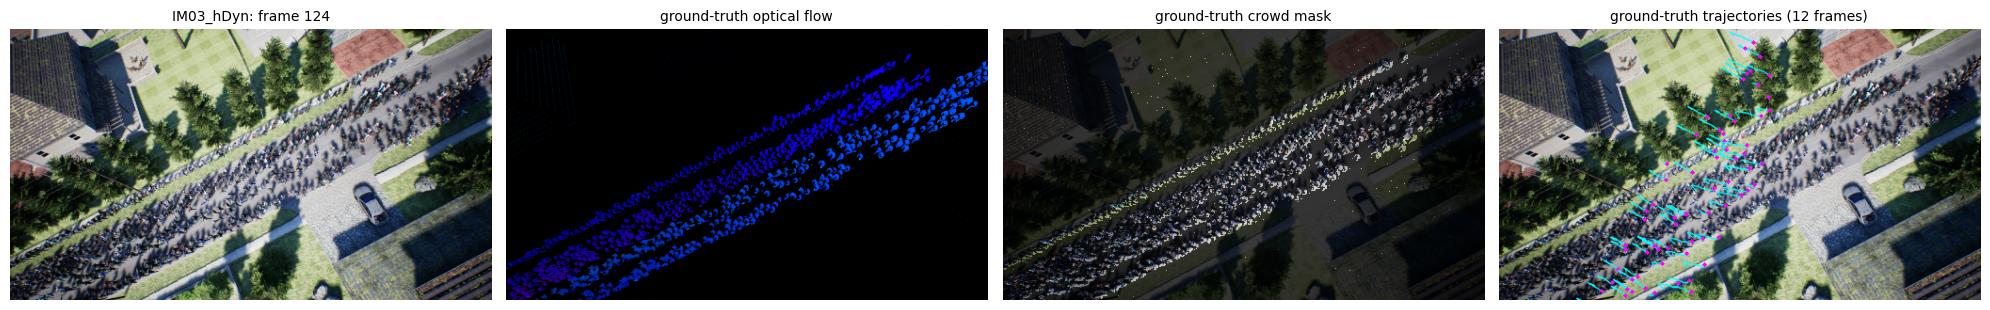

In [15]:
# ---- dataset visualisation: frame, ground-truth flow, mask, ground-truth trajectories of one scene ----------------------------------
_sc = SCENES[len(SCENES) // 2]; _ws = work_size(_sc.orig_size[0], _sc.orig_size[1], 512); _j = _sc.n_pairs // 2
_gt = load_flow(_sc, _j, _ws); _fr = load_frames(_sc, [_j], _ws)[0]; _mk = load_masks(_sc, _j, _ws); _tiles = [(_fr, f"{_sc.name}: frame {_j}"), (flow_to_color(_gt), "ground-truth optical flow")]
if _mk is not None: _tiles.append((np.where(_mk[..., None], _fr, (_fr * 0.25).astype(np.uint8)), "ground-truth crowd mask"))
_trs, _ = load_trajectories(_sc, max_tracks=300)
if _trs is not None:
    _sx, _sy = _ws[0] / _sc.orig_size[0], _ws[1] / _sc.orig_size[1]; _t0 = max(0, min(_j, len(_trs) - 12)); _tiles.append((draw_tracks(_fr, _trs[_t0:_t0 + 12] * np.array([_sx, _sy], np.float32)), "ground-truth trajectories (12 frames)"))
show_grid([t[0] for t in _tiles], [t[1] for t in _tiles], ncols=len(_tiles), figsize=(5 * len(_tiles), 3.4), save=os.path.join(FIG_DIR, "tub_dataset_overview.png")); plt.show()


## 4. Train / validation / test split (scene groups)

In [16]:
# ---- train / validation / test split at SCENE-GROUP level (complete groups, never individual frames) -------------------------------------
SPLIT = split_groups([s.group for s in SCENES], seed=SEED, n_val=1, n_test=1); _sp_path = os.path.join(METRICS_DIR, "scene_split.json")
if os.path.isfile(_sp_path):                                       # the split written by the first notebook that ran is reused by every notebook (no accidental re-splitting)
    _saved = json.load(open(_sp_path))["split"]
    if {k: sorted(v) for k, v in _saved.items()} != {k: sorted(v) for k, v in SPLIT.items()}: print("[info] using the split saved in", _sp_path, "(differs from the recomputed one: different seed / scene list?)"); SPLIT = _saved
print_split(SPLIT, SCENES)
TRAIN_SC, VAL_SC, TEST_SC = (scenes_of(SCENES, SPLIT[k]) for k in ("train", "val", "test"))
train_groups, val_groups, test_groups = (set(SPLIT[k]) for k in ("train", "val", "test"))
assert len(TRAIN_SC) > 0 and len(VAL_SC) > 0 and len(TEST_SC) > 0, "need at least 3 scene groups (train / validation / test)"
assert not train_groups & val_groups and not train_groups & test_groups and not val_groups & test_groups, "LEAK: a scene group appears in two splits"
assert {s.name for s in TRAIN_SC}.isdisjoint({s.name for s in VAL_SC} | {s.name for s in TEST_SC})
print("\nRULES: model weights / reference scales / feature scaler / crowd-regime edges / label thresholds / baseline statistics -> fitted on TRAIN only;")
print("       thresholds, cut-points and model selection -> tuned on VALIDATION only;  TEST -> reported once at the end.")
json.dump(dict(split=SPLIT, groups=SCENE_GROUPS, seed=SEED), open(os.path.join(METRICS_DIR, "scene_split.json"), "w"), indent=2)


SEQUENCE-LEVEL SPLIT (no frame of a scene appears in more than one subset):
  TRAIN  groups=['IM01', 'IM02', 'IM04']  scenes=['IM01', 'IM01_hDyn', 'IM02', 'IM02_hDyn', 'IM04', 'IM04_hDyn']  frames=1800
  VAL    groups=['IM03']  scenes=['IM03', 'IM03_hDyn']  frames=500
  TEST   groups=['IM05']  scenes=['IM05', 'IM05_hDyn']  frames=900

RULES: model weights / reference scales / feature scaler / crowd-regime edges / label thresholds / baseline statistics -> fitted on TRAIN only;
       thresholds, cut-points and model selection -> tuned on VALIDATION only;  TEST -> reported once at the end.


## 5. Motion configuration and working resolution (validation)

In [17]:
# ---- motion configuration ----------------------------------------------------------------------------------------------------------
MOTION_TRAIN_CFG = MOTION_TRAIN or dict(epochs=30 if DEVICE.type == "cuda" else 10, items_per_epoch=2400 if DEVICE.type == "cuda" else 600, batch=8, crop=256 if DEVICE.type == "cuda" else 160, base=24, lr=1e-3)
MOTION_MODEL_PATH = os.path.join(MODELS_DIR, "motion_model.pth"); FLOW_SELECTION_PATH = os.path.join(MODELS_DIR, "flow_selection.json")
MOTION_MAX_PAIRS_EVAL = 10 if SMOKE_TEST else 40
print("motion training config:", MOTION_TRAIN_CFG, "| work widths compared on validation:", MOTION_WIDTHS)


motion training config: {'epochs': 10, 'items_per_epoch': 600, 'batch': 8, 'crop': 160, 'base': 24, 'lr': 0.001} | work widths compared on validation: [256, 384, 512, 640]


In [18]:
# ---- 6.0 choose the working resolution on VALIDATION: DIS vs the zero-flow baseline inside the crowd mask --------------------------------
def sweep_width(width, scenes, n_pairs=10):
    dis, zero = DIS(), ZeroFlow(); rows = []
    for sc in scenes:
        if not sc.has_flow: continue
        ws = work_size(sc.orig_size[0], sc.orig_size[1], width)
        for j in np.unique(np.linspace(0, sc.n_pairs - 1, n_pairs).astype(int)):
            a, b, g, m = sc.frame(j, ws), sc.frame(j + 1, ws), sc.gt_flow(j, ws), sc.mask(j, ws)
            for nm, est in (("dis", dis), ("zero", zero)):
                mt = flow_metrics(est(a, b), g, m); rows.append(dict(width=width, scene=sc.name, est=nm, EPE=mt["EPE"], EPE_masked=mt["EPE_masked"] if np.isfinite(mt["EPE_masked"]) else mt["EPE"]))
    return pd.DataFrame(rows)
_sw = pd.concat([sweep_width(w, VAL_SC) for w in MOTION_WIDTHS]); _g = _sw.groupby(["width", "est"]).EPE_masked.mean().unstack(); _g["dis / zero"] = _g["dis"] / _g["zero"]; display(_g.round(4))
WIDTH = int(_g["dis / zero"].idxmin()); print("chosen work width:", WIDTH, "| DIS/zero masked-EPE ratio:", round(float(_g.loc[WIDTH, "dis / zero"]), 3))
if _g.loc[WIDTH, "dis / zero"] >= 1: print("[WARNING] classical flow does not beat the zero-flow baseline inside the crowd mask on validation at any width - motion statistics will be noisy.")
WCACHE = WorkCache(os.path.join(CACHE_DIR, "work_cache"), WIDTH)
for _sc_ in SCENES: WCACHE.build(_sc_, verbose=False)
print("work-resolution cache ready for", len(SCENES), "scenes")


est,dis,zero,dis / zero
width,,,
256,0.1360,0.2102,0.6471
384,0.1888,0.3492,0.5406
512,0.2236,0.5234,0.4271
640,0.2386,0.7438,0.3207


chosen work width: 640 | DIS/zero masked-EPE ratio: 0.321
work-resolution cache ready for 10 scenes


## 6. Optical-flow baselines (validation)

In [19]:
# ---- 6.1 optical-flow BASELINES evaluated on VALIDATION: zero flow, Farneback, DIS (+ optional pretrained RAFT-small) --------------------
ESTS = classical_estimators()
if USE_RAFT:
    _r = RAFTSmall.create(DEVICE)
    if _r is not None: ESTS["raft_small"] = _r
VAL_TABLES = [evaluate_estimator(est, VAL_SC, WCACHE, MOTION_MAX_PAIRS_EVAL) for est in ESTS.values()]
_cols = ["EPE", "EPE_masked", "MAE", "RMSE", "angular_deg", "dir_consistency"]; display(pd.concat(VAL_TABLES).groupby("estimator")[_cols].mean().round(4))


,EPE,EPE_masked,MAE,RMSE,angular_deg,dir_consistency
estimator,,,,,,
dis,0.6215,0.3141,0.3946,0.5252,12.5705,0.9205
farneback,0.6382,0.3510,0.4038,0.5409,15.9094,0.8906
raft_small,0.5937,0.6423,0.3796,0.4871,44.9349,0.5847
zero,0.0718,0.8023,0.0437,0.1837,90.0000,0.0000


## 7. MotionNetV2 training

[motion-net] ep  1/10 train 0.5682 | val EPE 0.3539 masked 0.3699 (prior/zero baseline 0.6628) | 383s *best*
[motion-net] ep  2/10 train 0.5549 | val EPE 0.3909 masked 0.3848 (prior/zero baseline 0.6628) | 371s
[motion-net] ep  3/10 train 0.4997 | val EPE 0.3994 masked 0.3212 (prior/zero baseline 0.6628) | 369s *best*
[motion-net] ep  4/10 train 0.4964 | val EPE 0.2863 masked 0.3523 (prior/zero baseline 0.6628) | 364s
[motion-net] ep  5/10 train 0.4807 | val EPE 0.3614 masked 0.3329 (prior/zero baseline 0.6628) | 363s
[motion-net] ep  6/10 train 0.4442 | val EPE 0.3437 masked 0.3335 (prior/zero baseline 0.6628) | 301s
[motion-net] ep  7/10 train 0.4765 | val EPE 0.3174 masked 0.3410 (prior/zero baseline 0.6628) | 170s
[motion-net] ep  8/10 train 0.4361 | val EPE 0.3121 masked 0.3520 (prior/zero baseline 0.6628) | 335s
early stopping


,epoch,train_loss,val_EPE,val_EPE_masked,val_EPE_prior_or_zero,time_s,is_best
0,1,0.5682,0.3539,0.3699,0.6628,382.8075,True
1,2,0.5549,0.3909,0.3848,0.6628,371.3386,NaN
2,3,0.4997,0.3994,0.3212,0.6628,368.9991,True
3,4,0.4964,0.2863,0.3523,0.6628,363.9598,NaN
4,5,0.4807,0.3614,0.3329,0.6628,362.8209,NaN
5,6,0.4442,0.3437,0.3335,0.6628,301.3379,NaN
6,7,0.4765,0.3174,0.3410,0.6628,169.6789,NaN
7,8,0.4361,0.3121,0.3520,0.6628,334.6634,NaN


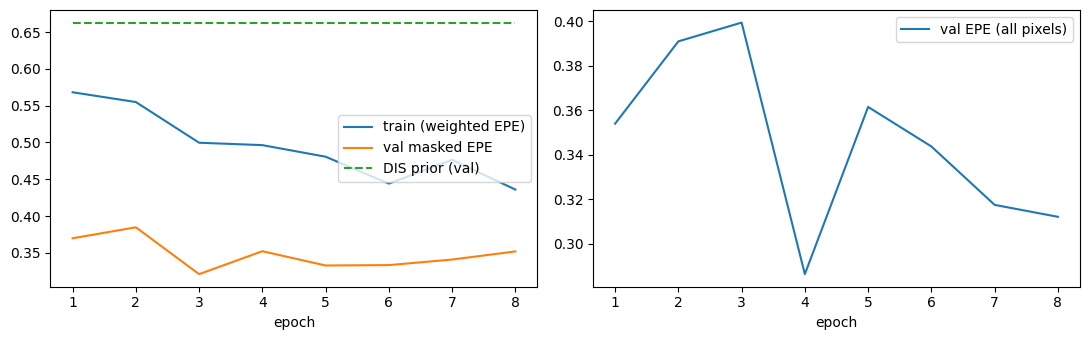

In [20]:
# ---- 6.2 MotionNetV2 (DIS-refinement U-Net, residual, zero-initialised head) trained on TRAIN scenes; model selection on validation masked EPE ----
MOTION_HIST = None
if TRAIN_MOTION_MODEL:
    MOTION_HIST = train_motion_net(TRAIN_SC, VAL_SC, WCACHE, MOTION_MODEL_PATH, device=DEVICE, seed=SEED, resume=True, extra_meta=dict(split=SPLIT, note="trained on TUB ground-truth flow; scene-group split"), **MOTION_TRAIN_CFG)
    display(MOTION_HIST.round(4)); MOTION_HIST.to_csv(os.path.join(METRICS_DIR, "motion_training_history.csv"), index=False)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5)); ax[0].plot(MOTION_HIST.epoch, MOTION_HIST.train_loss, label="train (weighted EPE)"); ax[0].plot(MOTION_HIST.epoch, MOTION_HIST.val_EPE_masked, label="val masked EPE"); ax[0].plot(MOTION_HIST.epoch, MOTION_HIST.val_EPE_prior_or_zero, "--", label="DIS prior (val)"); ax[0].legend(); ax[0].set_xlabel("epoch")
    ax[1].plot(MOTION_HIST.epoch, MOTION_HIST.val_EPE, label="val EPE (all pixels)"); ax[1].legend(); ax[1].set_xlabel("epoch"); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "motion_training.png"), dpi=100); plt.show()
if os.path.isfile(MOTION_MODEL_PATH):
    try: ESTS["motionnet_v2"] = MotionNetEstimator(MOTION_MODEL_PATH, DEVICE); VAL_TABLES.append(evaluate_estimator(ESTS["motionnet_v2"], VAL_SC, WCACHE, MOTION_MAX_PAIRS_EVAL))
    except Exception as e: print("[warn] MotionNetV2 could not be loaded:", e)
else: print("MotionNetV2 not available (TRAIN_MOTION_MODEL=False and no saved motion_model.pth).")


## 8. Validation selection and test evaluation (BASELINE vs ENHANCED)

In [21]:
# ---- 6.3 selection on VALIDATION (never assumes MotionNetV2 or DIS is better) -> 6.4 test evaluation (reported, never used for selection) ----
VT = pd.concat(VAL_TABLES); _vs = VT.groupby("estimator")[_cols].mean(); display(_vs.round(4))
_cand = _vs.drop(index="zero", errors="ignore"); SELECTED_FLOW = _cand["EPE_masked"].idxmin()
_classical = _cand.drop(index="motionnet_v2", errors="ignore"); BASELINE_FLOW = _classical["EPE_masked"].idxmin()
print(f"BASELINE (best classical: {BASELINE_FLOW}) VALIDATION masked EPE: {_classical.loc[BASELINE_FLOW, 'EPE_masked']:.4f}   (zero-flow reference {_vs.loc['zero', 'EPE_masked']:.4f})")
if "motionnet_v2" in _cand.index: print(f"NEW MODEL (motionnet_v2) VALIDATION masked EPE: {_cand.loc['motionnet_v2', 'EPE_masked']:.4f}")
print("SELECTED MODEL:", ("ENHANCED" if SELECTED_FLOW == "motionnet_v2" else "BASELINE"), f"-> {SELECTED_FLOW}   (rule: lowest validation masked EPE among non-zero estimators; lower EPE is better)")
if _cand.loc[SELECTED_FLOW, "EPE_masked"] >= _vs.loc["zero", "EPE_masked"]: print("[WARNING] the selected estimator does NOT beat zero flow inside the crowd mask on validation.")
TT = pd.concat([evaluate_estimator(est, TEST_SC, WCACHE, MOTION_MAX_PAIRS_EVAL) for est in ESTS.values()]); _tcols = _cols + ["GT_mag", "GT_mag_masked"]
MOTION_TEST_ALL = TT.groupby("estimator")[_tcols].mean(); display(MOTION_TEST_ALL.round(4)); display(TT[["scene", "estimator"] + _tcols].round(4))
MOTION_TEST = {k: float(MOTION_TEST_ALL.loc[SELECTED_FLOW, k]) for k in _cols}
pd.concat([VT.assign(subset="validation"), TT.assign(subset="test")]).to_csv(os.path.join(METRICS_DIR, "motion_metrics.csv"), index=False)
json.dump(dict(selected=SELECTED_FLOW, baseline=BASELINE_FLOW, work_width=WIDTH, seed=SEED, split=SPLIT, selection_rule="lowest validation masked EPE among non-zero estimators", validation=_vs.round(5).to_dict(), test_overall=MOTION_TEST_ALL.round(5).to_dict(),
               motion_model=MOTION_MODEL_PATH if SELECTED_FLOW == "motionnet_v2" else None, note="Stage A estimates motion only. Ground-truth flow is for training/evaluation, never for inference."), open(FLOW_SELECTION_PATH, "w"), indent=2)
RUN_META.update(selected_motion_estimator=SELECTED_FLOW, work_width=WIDTH); print("saved ->", FLOW_SELECTION_PATH)


,EPE,EPE_masked,MAE,RMSE,angular_deg,dir_consistency
estimator,,,,,,
dis,0.6215,0.3141,0.3946,0.5252,12.5705,0.9205
farneback,0.6382,0.3510,0.4038,0.5409,15.9094,0.8906
motionnet_v2,0.3875,0.3230,0.2450,0.3570,13.9929,0.9146
raft_small,0.5937,0.6423,0.3796,0.4871,44.9349,0.5847
zero,0.0718,0.8023,0.0437,0.1837,90.0000,0.0000


BASELINE (best classical: dis) VALIDATION masked EPE: 0.3141   (zero-flow reference 0.8023)
NEW MODEL (motionnet_v2) VALIDATION masked EPE: 0.3230
SELECTED MODEL: BASELINE -> dis   (rule: lowest validation masked EPE among non-zero estimators; lower EPE is better)


,EPE,EPE_masked,MAE,RMSE,angular_deg,dir_consistency,GT_mag,GT_mag_masked
estimator,,,,,,,,
dis,1.7638,0.5510,1.1311,1.5710,11.9852,0.9310,0.3317,1.8878
farneback,1.5099,0.6029,0.9659,1.4229,13.8512,0.9178,0.3317,1.8878
motionnet_v2,0.8961,0.7640,0.5701,0.8368,14.3291,0.9201,0.3317,1.8878
raft_small,1.7818,0.6752,1.1426,1.5309,17.8178,0.8894,0.3317,1.8878
zero,0.3317,1.8878,0.2112,0.6267,90.0000,0.0000,0.3317,1.8878


,scene,estimator,EPE,EPE_masked,MAE,RMSE,angular_deg,dir_consistency,GT_mag,GT_mag_masked
0,IM05,zero,0.3029,1.3100,0.1919,0.5157,90.0000,0.0000,0.3029,1.3100
1,IM05_hDyn,zero,0.3605,2.4656,0.2304,0.7377,90.0000,0.0000,0.3605,2.4656
0,IM05,farneback,0.6813,0.4412,0.4310,0.7459,11.5525,0.9410,0.3029,1.3100
1,IM05_hDyn,farneback,2.3385,0.7647,1.5007,2.0999,16.1499,0.8946,0.3605,2.4656
0,IM05,dis,0.5777,0.3659,0.3635,0.6776,9.0571,0.9554,0.3029,1.3100
1,IM05_hDyn,dis,2.9499,0.7362,1.8987,2.4643,14.9134,0.9067,0.3605,2.4656
0,IM05,raft_small,0.6910,0.5396,0.4360,0.6706,17.8570,0.8951,0.3029,1.3100
1,IM05_hDyn,raft_small,2.8727,0.8109,1.8493,2.3912,17.7786,0.8836,0.3605,2.4656
0,IM05,motionnet_v2,0.3881,0.4429,0.2471,0.4541,10.8141,0.9484,0.3029,1.3100
1,IM05_hDyn,motionnet_v2,1.4041,1.0851,0.8930,1.2194,17.8441,0.8918,0.3605,2.4656


saved -> c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\models\flow_selection.json


## 9. Visualisation and summary

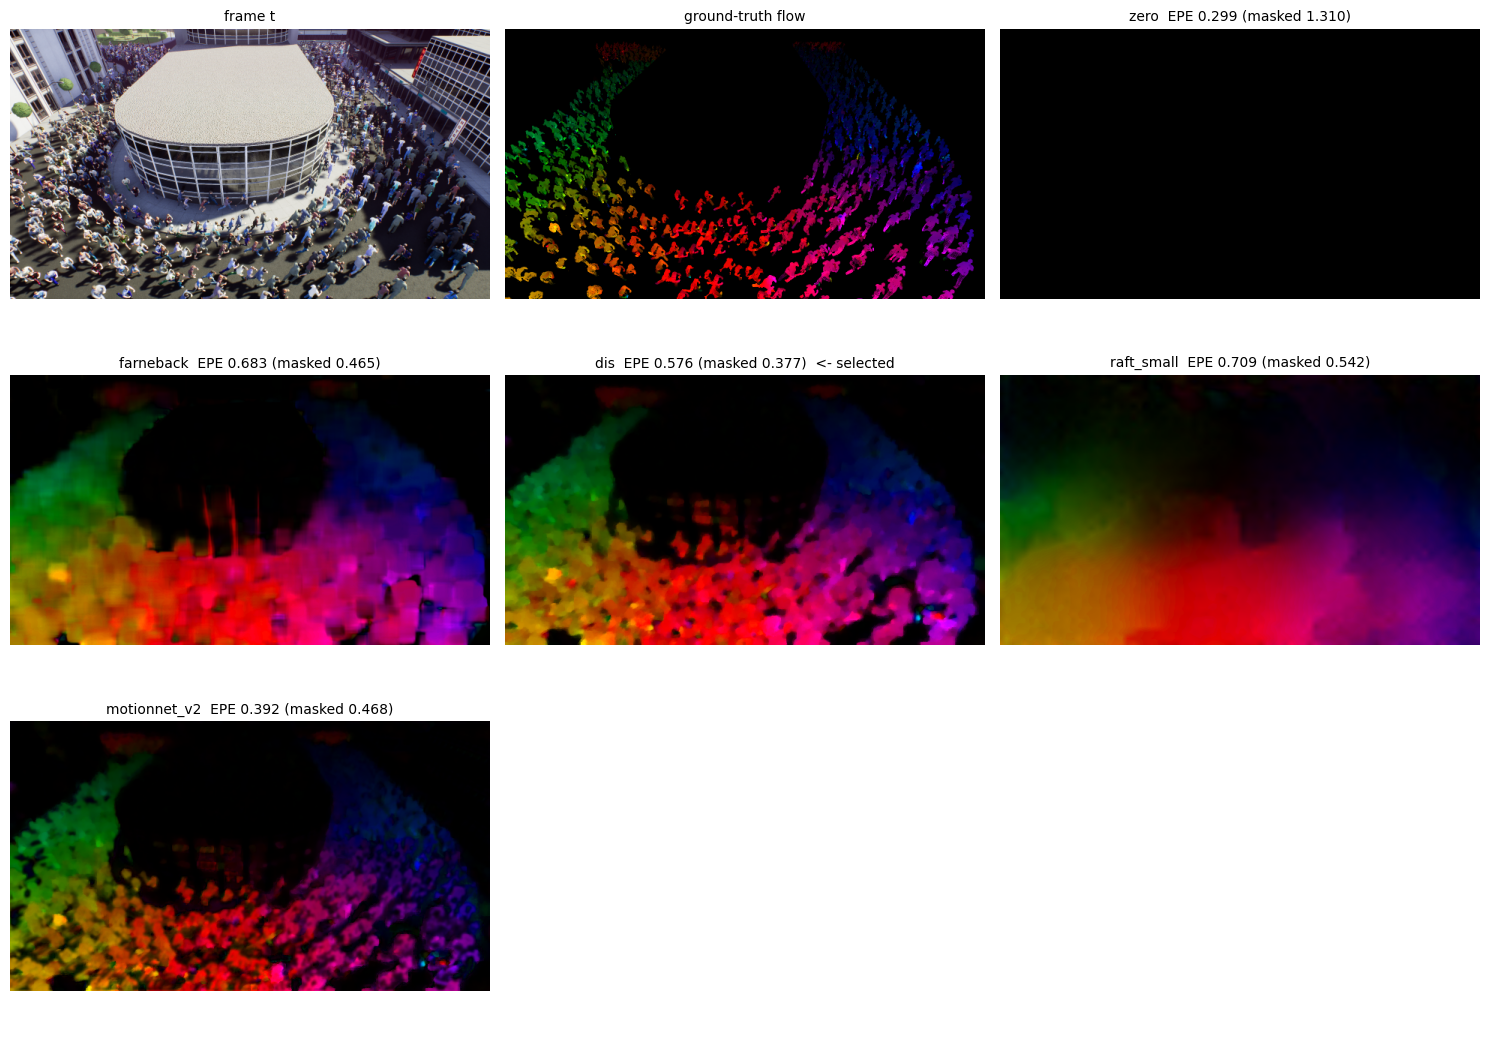

In [22]:
# ---- 6.5 visual check on one TEST pair: ground truth vs every estimator --------------------------------------------------------------
_sc = TEST_SC[0]; _j = _sc.n_pairs // 2; _fr = WCACHE.frames(_sc); _gt = np.asarray(WCACHE.flow(_sc)[_j], np.float32); _mm_ = WCACHE.masks(_sc); _mk = np.asarray(_mm_[min(_j, len(_mm_) - 1)]) if _mm_ is not None else None
_a, _b = np.ascontiguousarray(_fr[_j]), np.ascontiguousarray(_fr[_j + 1]); _mx = max(float(np.percentile(np.linalg.norm(_gt, axis=-1), 99)), 0.3); _imgs, _ttl = [_a, flow_to_color(_gt, _mx)], ["frame t", "ground-truth flow"]
for _nm, _est in ESTS.items():
    _p = _est(_a, _b); _imgs.append(flow_to_color(_p, _mx)); _mt = flow_metrics(_p, _gt, _mk); _ttl.append(f"{_nm}  EPE {_mt['EPE']:.3f} (masked {_mt['EPE_masked']:.3f})" + ("  <- selected" if _nm == SELECTED_FLOW else ""))
show_grid(_imgs, _ttl, ncols=3, save=os.path.join(FIG_DIR, "motion_estimators_example.png")); plt.show()


In [23]:
print("=" * 90); print("NOTEBOOK 02 - SUMMARY"); print("=" * 90)
print("Selected motion estimator :", SELECTED_FLOW, f"(baseline = {BASELINE_FLOW}) | work width {WIDTH}")
print("Test metrics              :", {k: round(v, 4) for k, v in MOTION_TEST.items()}); print("Files                     :", FLOW_SELECTION_PATH, "|", MOTION_MODEL_PATH if os.path.isfile(MOTION_MODEL_PATH) else "(no MotionNetV2 file)", "\nNext: notebook 03_Abnormal_Motion_Detection")


NOTEBOOK 02 - SUMMARY
Selected motion estimator : dis (baseline = dis) | work width 640
Test metrics              : {'EPE': 1.7638, 'EPE_masked': 0.551, 'MAE': 1.1311, 'RMSE': 1.571, 'angular_deg': 11.9852, 'dir_consistency': 0.931}
Files                     : c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\models\flow_selection.json | c:\main project\stampede-risk-estimation\notebook_try\crowdrisk_outputs\models\motion_model.pth 
Next: notebook 03_Abnormal_Motion_Detection
